# DeepTuneIO Analyzer — Module 10: Access-Pattern Visualization

Notebook with configurable 3D camera angles for selecting campaigns, JobIDs and visualization profiles. Scientific plotting logic remains in `Module/Access_Pattern_Visualization/`.

**New:** `dxt_timeline` plots MPI-IO and POSIX rank-versus-runtime operations colored by request-size category.


## Dynamic titles (v1.7)\nThe module reads `3_Summary_Global_*.csv` for the selected JobID. Figures display a single main title and up to two metadata lines; Lustre OST labels are derived only from explicit configuration.\n

In [7]:
from pathlib import Path
import sys
from importlib.util import spec_from_file_location, module_from_spec

CODE_ROOT = Path.cwd()  # Carpeta que contiene Module/
MODULE_DIR = (CODE_ROOT / "Module").resolve()
if not MODULE_DIR.is_dir():
    raise FileNotFoundError(f"No se encuentra la carpeta Module: {MODULE_DIR}")
MODULE_FILE = MODULE_DIR / "10_access_pattern_visualization.py"

if not MODULE_FILE.is_file():
    raise FileNotFoundError(f"No se encuentra el módulo: {MODULE_FILE}")

spec = spec_from_file_location("deeptuneio_access_viz10", MODULE_FILE)
module10 = module_from_spec(spec)
sys.modules[spec.name] = module10
spec.loader.exec_module(module10)

print("Module :", MODULE_FILE)
print("Version:", module10.VERSION)


Module : F:\NoteBooks\CORA_DR_UAB\Tesis\Scripts\DeepTuneIO\10_Visualization\Access_Pattern\Module\10_access_pattern_visualization.py
Version: 1.8.0


In [8]:
PROJECT_ROOT = Path(r"D:\DL_Experiments\CORA_DR_UAB").resolve()
ARTICLE_ID = "Tesis"

EVENT = "Tesis"

CAMPAIGNS = {
    "DeepGalaxy": {
        "DG_bw512_f3c5x64": {
            "scenarios": ["lustre_1ost", "lustre_2ost", "lustre_4ost", "nfs_SnGPU_e1"],
            "file_format": ".hdf5",
        },
    },
    "DLIOv1": {
        "HDF5_64bs": {"scenarios": ["lustre_ost"], "file_format": ".h5"},
        "NPZ_64bs": {"scenarios": ["lustre_ost"], "file_format": ".npz"},
        "TFRecord_256kts_64bs": {"scenarios": ["lustre_ost"], "file_format": ".tfrecords"},
        "TFRecord_1mts_64bs": {"scenarios": ["lustre_ost"], "file_format": ".tfrecords"},
    },
}

APPLICATION_POS = 1
DATASET_POS = 1
SCENARIO_POS = 4

APPLICATION = list(CAMPAIGNS)[APPLICATION_POS - 1]
DATASET_GROUP = list(CAMPAIGNS[APPLICATION])[DATASET_POS - 1]
SCENARIO = CAMPAIGNS[APPLICATION][DATASET_GROUP]["scenarios"][SCENARIO_POS - 1]
FILE_FORMAT = CAMPAIGNS[APPLICATION][DATASET_GROUP]["file_format"]

CAMPAIGN_ROOT = (
    PROJECT_ROOT / ARTICLE_ID / "Data"
    / APPLICATION / DATASET_GROUP / SCENARIO
)

print(APPLICATION, DATASET_GROUP, SCENARIO, FILE_FORMAT)
print("Campaign:", CAMPAIGN_ROOT)


DeepGalaxy DG_bw512_f3c5x64 nfs_SnGPU_e1 .hdf5
Campaign: D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1


## Select the execution dynamically from the experiment matrix

The selector is now **matrix-first**: `experiment_matrix_*.csv` is the source of
truth for configuration metadata, while DXT is used only to confirm that a JobID
has detailed events available.

Normalized modes:
- DeepGalaxy `shared` → `shared`
- DeepGalaxy `shared_reload_shuffle` → `shared_reload_shuffle`
- DLIO `shared` → `shared`
- DLIO `multi` → `file_per_process`


In [9]:
JOB_TABLE = module10.build_job_selection_table(
    CAMPAIGN_ROOT,
    application=APPLICATION,
    scenario=SCENARIO,
    file_format=FILE_FORMAT,
)

DISPLAY_COLUMNS = [
    "job_id",
    "nodes",
    "process_io",
    "replicate",
    "dxt_available",
    "dxt_events",
]

display(
    JOB_TABLE[
        [c for c in DISPLAY_COLUMNS if c in JOB_TABLE.columns]
    ]
)


,job_id,nodes,process_io,replicate,dxt_available,dxt_events
0,4942237,1,4,1,True,262061
1,5175899,1,4,2,True,262061
2,4948089,1,4,1,True,262061
3,5186375,1,4,2,True,262061
4,5317261,1,4,3,True,262061
5,4998168,2,8,1,True,508104
6,5326016,2,8,2,True,508104
7,5346216,2,8,3,True,508104
8,5124492,2,8,1,True,524189
9,5136376,2,8,2,True,524189


In [20]:
# Optional selector.
TARGET_NODES = None
TARGET_PROCESSES = None
TARGET_MODE = "all"       # shared | shared_reload_shuffle | file_per_process | all
TARGET_FILESYSTEM = "all"
TARGET_OST = None

JOB_CANDIDATES = module10.filter_job_selection_table(
    JOB_TABLE,
    nodes=TARGET_NODES,
    process_io=TARGET_PROCESSES,
    data_loading_mode=TARGET_MODE,
    filesystem=TARGET_FILESYSTEM,
    stripe_count=TARGET_OST,
    dxt_only=True,
)

display(JOB_CANDIDATES[[c for c in DISPLAY_COLUMNS if c in JOB_CANDIDATES.columns]])

if len(JOB_CANDIDATES) == 1:
    JOB_ID = int(JOB_CANDIDATES.iloc[0]["job_id"])
    print("Selected JobID:", JOB_ID)
else:
    JOB_ID = None
    print(f"{len(JOB_CANDIDATES)} DXT candidates found. Refine the filters or choose a JobID from the table.")


,job_id,nodes,process_io,replicate,dxt_available,dxt_events
0,4942237,1,4,1,True,262061
1,5175899,1,4,2,True,262061
2,4948089,1,4,1,True,262061
3,5186375,1,4,2,True,262061
4,5317261,1,4,3,True,262061
5,4998168,2,8,1,True,508104
6,5326016,2,8,2,True,508104
7,5346216,2,8,3,True,508104
8,5124492,2,8,1,True,524189
9,5136376,2,8,2,True,524189


25 DXT candidates found. Refine the filters or choose a JobID from the table.


In [48]:
# You may also override the automatic selection manually after inspecting the table:
#JOB_ID = 5333326  # DeepGalaxy HDF5 Shared/Reload/Shuffle 16N64p NFS
#JOB_ID = 5364632 # DeepGalaxy HDF5 Shared 16N64p NFS
#JOB_ID = 5333197  # DeepGalaxy HDF5 Shared 16N64p NFS
#JOB_ID = 4942237 # DeepGalaxy HDF5 Shared 1N6p NFS
#JOB_ID = 5175899  # DeepGalaxy HDF5 Shared 1N6p NFS
#JOB_ID = 4948089 # DeepGalaxy HDF5 Shared 1N6p NFS
#JOB_ID = 5185108  # DeepGalaxy HDF5 Shared 4N16p NFS
JOB_ID = 5352800 # DeepGalaxy HDF5 Shared 4N16p NFS


In [49]:
# Selección manual opcional. None conserva la selección dinámica de la tabla.
MANUAL_JOB_ID = None  # Ejemplo: 5333326 (solo si pertenece a esta campaña)
if MANUAL_JOB_ID is not None:
    available_ids = set(JOB_TABLE["job_id"].dropna().astype(str))
    if str(MANUAL_JOB_ID) not in available_ids:
        raise ValueError(f"JobID {MANUAL_JOB_ID} no figura en la campaña seleccionada")
    JOB_ID = int(MANUAL_JOB_ID)
print("JobID seleccionado:", JOB_ID)


JobID seleccionado: 5352800


In [50]:
# ============================================================
# Access-pattern visualization profile
# ============================================================
#
# Select which family of DXT access-pattern figures to generate.
#
# Available options:
#
# "process3d"
#     Process-oriented spatial/temporal analysis.
#     Generates:
#       01_spatial_temporal_3d
#          X = I/O Process
#          Y = Operation Order
#          Z = File Offset
#          Color/size = Request Size
#
#       04_spatial_pattern_by_process
#          X = I/O Process
#          Y = File Offset
#          Color/size = Request Size
#
# "temporal2d"
#     Classical 2D spatial and temporal analysis.
#     Generates:
#       02_spatial_pattern
#          X = Operation Order
#          Y = File Offset
#          Color/size = Request Size
#
#       03_temporal_pattern
#          X = Start Time
#          Y = File Offset
#          Color/size = Request Size
#
# "temporal3d"
#     Real-time process-aware spatio-temporal analysis.
#     Generates:
#       07_spatial_temporal_time_3d
#          X = I/O Process
#          Y = Start Time
#          Z = File Offset
#          Color/size = Request Size
#
#       03_temporal_pattern
#          X = Start Time
#          Y = File Offset
#          Color/size = Request Size
#
# "hist"
#     Spatial access pattern with marginal histograms.
#     Generates:
#       05_spatial_pattern_histograms
#
# "ost"
#     DXT-reported OST association overview.
#     Generates:
#       06_ost_association_overview
#
# "dxt_timeline"
#     DXT rank-versus-runtime timeline (MPI-IO and POSIX panels).
#     Each operation is a segment from start to end time; color encodes request size.
#     Outputs 08_dxt_rank_timeline.png and .pdf.
#     Interfaces are only separated when the source records identify them.
#
# "all"
#     Generates all available access-pattern figure families:
#       01, 02, 03, 04, 05, 06 and 07.
#
# Examples:
#     PROFILE = "process3d"
#     PROFILE = "temporal2d"
#     PROFILE = "temporal3d"
#     PROFILE = "hist"
#     PROFILE = "ost"
#     PROFILE = "dxt_timeline"
#     PROFILE = "all"
#     PROFILE = "contention"
#
# ============================================================

PROFILE = "contention"  # Other options: process3d, temporal2d, temporal3d, hist, ost, dxt_timeline, all

In [51]:
# You may also override the automatic selection manually after inspecting the table:
# JOB_ID = 4935078

# all | read | write
OPERATION = "read"

# Orientación configurable de process3d y temporal3d (grados).
VIEW_ELEV = 15
VIEW_AZIM = -25


# Optional deterministic visual downsampling for very dense traces.
# Keep None for exact full-trace figures.
MIN_OVERLAP_S = 0.0  # solapamiento temporal mínimo
MAX_CONTENTION_PAIRS = 900000
RESOURCE_MODE = "auto"  # auto | ost | nfs | none  # límite de seguridad
MAX_EVENTS = None

print("JobID:", JOB_ID)


JobID: 5352800


In [52]:
# El módulo 10 actualizado acepta ángulos por argumentos.
args = [
    "--campaign-root", str(CAMPAIGN_ROOT),
    "--application", APPLICATION,
    "--dataset-group", DATASET_GROUP,
    "--scenario", SCENARIO,
    "--file-format", FILE_FORMAT,
    "--event", EVENT,
    "--operation", OPERATION,
    "--profile", PROFILE,
    "--view-elev", str(VIEW_ELEV),
    "--view-azim", str(VIEW_AZIM),
    "--min-overlap-s", str(MIN_OVERLAP_S),
    "--max-contention-pairs", str(MAX_CONTENTION_PAIRS),
    "--resource-mode", RESOURCE_MODE,
]

if JOB_ID is not None:
    args += ["--job-id", str(JOB_ID)]
if MAX_EVENTS is not None:
    args += ["--max-events", str(MAX_EVENTS)]

print("Ejecutando módulo 10:", args)
return_code = module10.main(args)
print("Return code:", return_code)
if return_code != 0:
    raise RuntimeError(f"Module 10 failed with return code {return_code}")


Ejecutando módulo 10: ['--campaign-root', 'D:\\DL_Experiments\\CORA_DR_UAB\\Tesis\\Data\\DeepGalaxy\\DG_bw512_f3c5x64\\nfs_SnGPU_e1', '--application', 'DeepGalaxy', '--dataset-group', 'DG_bw512_f3c5x64', '--scenario', 'nfs_SnGPU_e1', '--file-format', '.hdf5', '--event', 'Tesis', '--operation', 'read', '--profile', 'contention', '--view-elev', '15', '--view-azim', '-25', '--min-overlap-s', '0.0', '--max-contention-pairs', '900000', '--resource-mode', 'auto', '--job-id', '5352800']
DeepTuneIO — Module 10: Access-Pattern Visualization
Campaign root : D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1
Application   : DeepGalaxy
Dataset group : DG_bw512_f3c5x64
Scenario      : nfs_SnGPU_e1
File format   : .hdf5
JobID         : 5352800
Operation     : read
Profile       : contention
Output        : D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Access_Pattern\job_5352800
Summary metadata: D:\DL_Experiments\CORA

## Article 01 — Fig. 10(b,d) spatial model

Version 1.1 adds the missing 2D spatial representation:

- **X:** I/O Process
- **Y:** File Offset
- **Color:** Read Request Size

A 4-process JobID reproduces the Fig. 10(b) model; a 64-process JobID reproduces the Fig. 10(d) model.

In [53]:
OUTPUT_ROOT = (
    CAMPAIGN_ROOT / "results" / "Figures" / "Access_Pattern"
    / (f"job_{JOB_ID}" if JOB_ID is not None else "campaign")
)

print("Outputs:", OUTPUT_ROOT)

if OUTPUT_ROOT.exists():
    for p in sorted(OUTPUT_ROOT.iterdir()):
        print(" -", p.name)


Outputs: D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Access_Pattern\job_5352800
 - 10_contention_affected_events.csv
 - 10_contention_cases_comparison.pdf
 - 10_contention_cases_comparison.png
 - 10_contention_three_cases_diagnostics.json
 - 10_contention_three_cases_pairs.csv
 - 11_contention_three_cases_timeline.pdf
 - 11_contention_three_cases_timeline.png
 - 12_contention_three_cases_by_process.pdf
 - 12_contention_three_cases_by_process.png
 - 13_exact_range_concurrent_io.pdf
 - 13_exact_range_concurrent_io.png
 - 14_partial_range_concurrent_io.pdf
 - 14_partial_range_concurrent_io.png
 - 15_shared_resource_concurrent_io.pdf
 - 15_shared_resource_concurrent_io.png
 - access_pattern_events_normalized.csv
 - access_pattern_summary.csv
 - access_pattern_visualization_manifest.json


## DXT rank timeline — notebook validation

Run the cells above with `PROFILE = "dxt_timeline"`. The figure uses the currently selected campaign, JobID and operation.

**Checks:** inspect generated files, verify PNG/PDF exist, and compare operation counts and interface labels with the original DXT source. A successful plot is not sufficient to validate scientific equivalence.


In [54]:
from pathlib import Path
from IPython.display import display, Image

# Validation/preview for the selected JobID.
expected = [OUTPUT_ROOT / "08_dxt_rank_timeline.png", OUTPUT_ROOT / "08_dxt_rank_timeline.pdf"]
for artifact in expected:
    print(("OK" if artifact.is_file() else "MISSING"), artifact)
if expected[0].is_file():
    display(Image(filename=str(expected[0])))
else:
    print("Check the profile output, source availability and the generated manifest.")


MISSING D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Access_Pattern\job_5352800\08_dxt_rank_timeline.png
MISSING D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Access_Pattern\job_5352800\08_dxt_rank_timeline.pdf
Check the profile output, source availability and the generated manifest.


In [55]:
from pathlib import Path
import pandas as pd

analysis_dir = (
    CAMPAIGN_ROOT
    / "results"
    / "Access_Pattern_DXT"
    / "Analysis"
)

traces_dir = (
    CAMPAIGN_ROOT
    / "results"
    / "Access_Pattern_DXT"
    / "Traces"
)

SOURCE_COMPARISON_JOB_ID = JOB_ID  # Use currently selected job

analysis_files = sorted(
    analysis_dir.glob(f"*{SOURCE_COMPARISON_JOB_ID}*_dxt_analysis.csv")
)

trace_files = sorted(
    traces_dir.glob(f"*{SOURCE_COMPARISON_JOB_ID}*_dxt.csv")
)

print("=" * 80)
print("DXT SOURCE COMPARISON")
print("=" * 80)

print("\nAnalysis files:")
for p in analysis_files:
    df = pd.read_csv(p)
    print(f"  {p.name}")
    print(f"    rows    : {len(df)}")
    print(f"    columns : {len(df.columns)}")

print("\nTrace files:")
for p in trace_files:
    df = pd.read_csv(p)
    print(f"  {p.name}")
    print(f"    rows    : {len(df)}")
    print(f"    columns : {len(df.columns)}")

if analysis_files and trace_files:

    a = pd.read_csv(analysis_files[0])
    t = pd.read_csv(trace_files[0])

    print("\n" + "=" * 80)
    print("STRUCTURAL COMPARISON")
    print("=" * 80)

    print("Analysis rows :", len(a))
    print("Trace rows    :", len(t))

    common = sorted(
        set(a.columns).intersection(t.columns)
    )

    print("Common columns:", len(common))

    print("\nAnalysis-only columns:")
    print(sorted(set(a.columns) - set(t.columns)))

    print("\nTrace-only columns:")
    print(sorted(set(t.columns) - set(a.columns)))

    print("\nCommon columns:")
    print(common)

DXT SOURCE COMPARISON

Analysis files:
  7_DG_N4p16e1_EfficientNetB4_outputbw512hdf5_ds36nc14_M0_nfs_5352800_FT3RESDT_dxt_analysis.csv
    rows    : 537258
    columns : 15

Trace files:
  7_DG_N4p16e1_EfficientNetB4_outputbw512hdf5_ds36nc14_M0_nfs_5352800_FT3RESDT_dxt.csv
    rows    : 537258
    columns : 10

STRUCTURAL COMPARISON
Analysis rows : 537258
Trace rows    : 537258
Common columns: 10

Analysis-only columns:
['Count Offset Gap', 'Latency(s)', 'Offsets Gap', 'Predicted_Sequence_Offset', 'Predicted_Strided_Offset']

Trace-only columns:
[]

Common columns:
['End_Time(s)', 'File_System', 'File_name', 'Nodes', 'Offset(bytes)', 'Operation_Type', 'Process_IO', 'Request_Size(bytes)', 'Start_Time(s)', 'Temporal_Order']


## Diagnóstico de contención: tres casos
`PROFILE="contention"` ejecuta A (offset/longitud idénticos), B (intervalos parcialmente solapados) y C (recurso compartido con evidencia OST o escenario NFS).
Las coincidencias son **candidatos**, no pruebas de degradación. Se generan CSV de pares, operaciones únicas, JSON de calidad y tres gráficos.


## Visualizaciones individuales de los casos A, B y C
Con `PROFILE="contention"` o `"all"` se generan `13_exact_range_concurrent_io`, `14_partial_range_concurrent_io` y `15_shared_resource_concurrent_io` en PNG y PDF. Los casos A/B muestran ejemplos reales de intervalos temporales y espaciales; C muestra ranks activos entre eventos candidatos, no una medición de congestión. El límite `MAX_CONTENTION_PAIRS` puede truncar el resultado: comprobar siempre el JSON de diagnóstico.


13_exact_range_concurrent_io


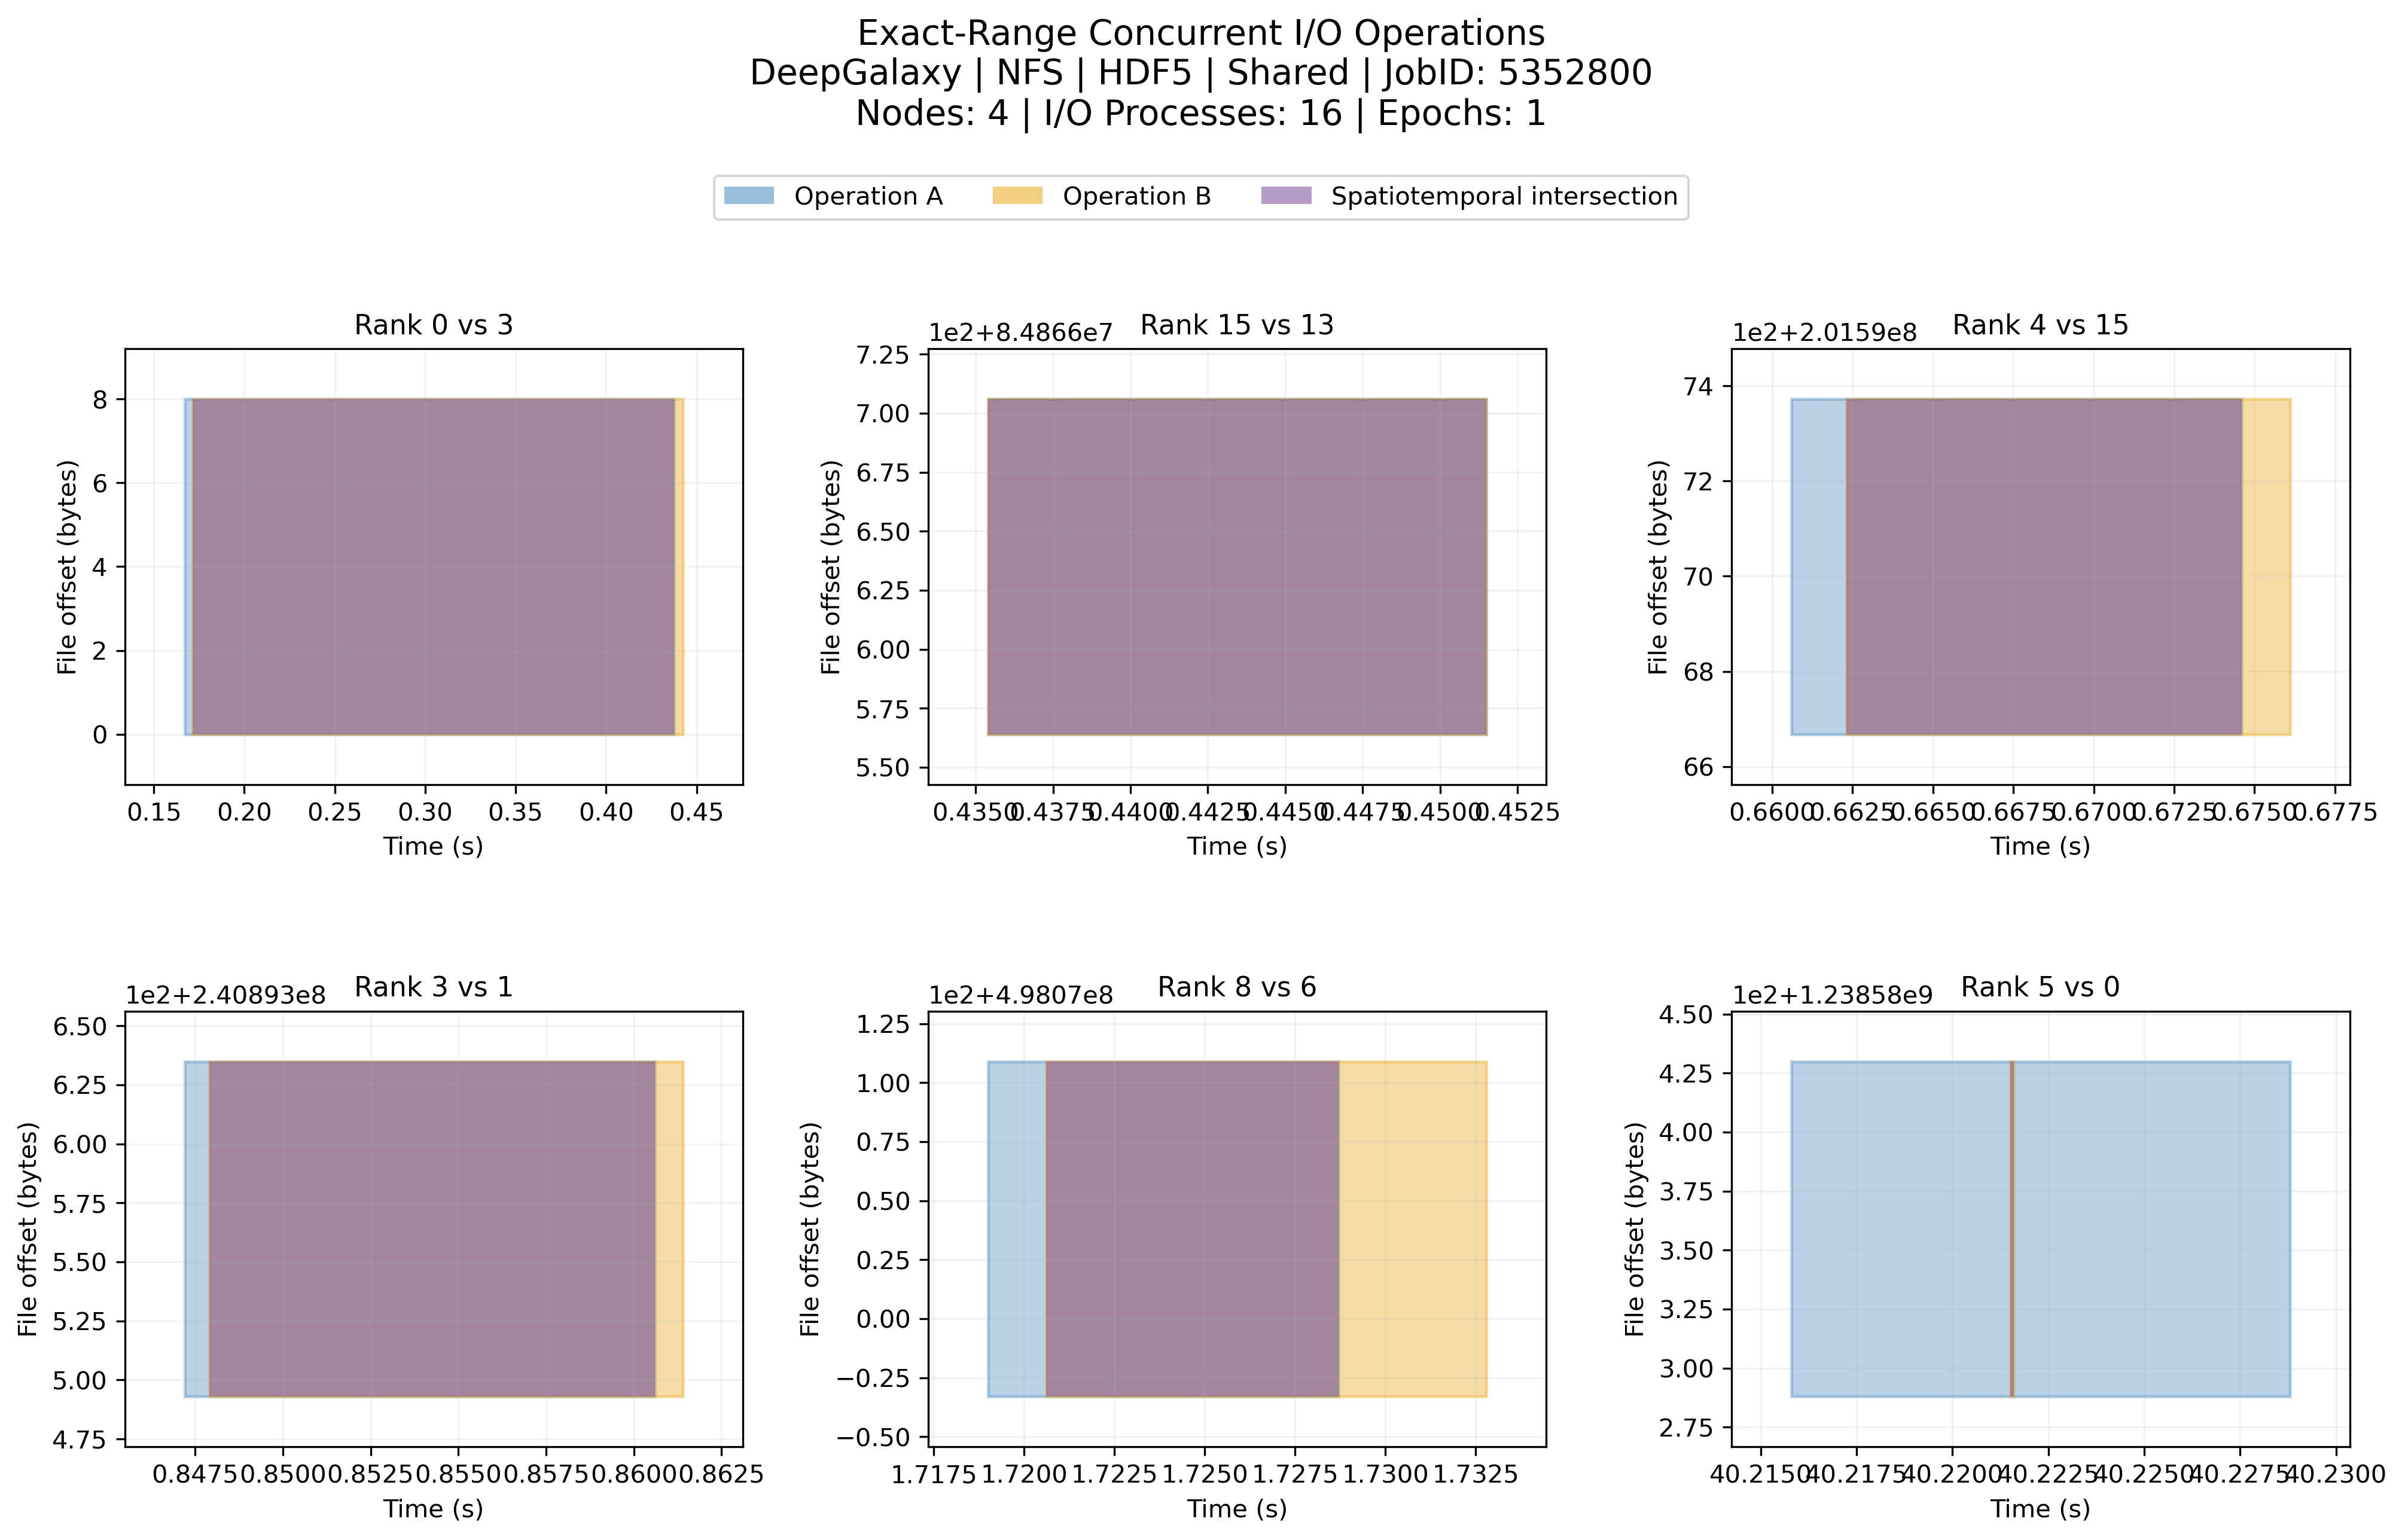

14_partial_range_concurrent_io


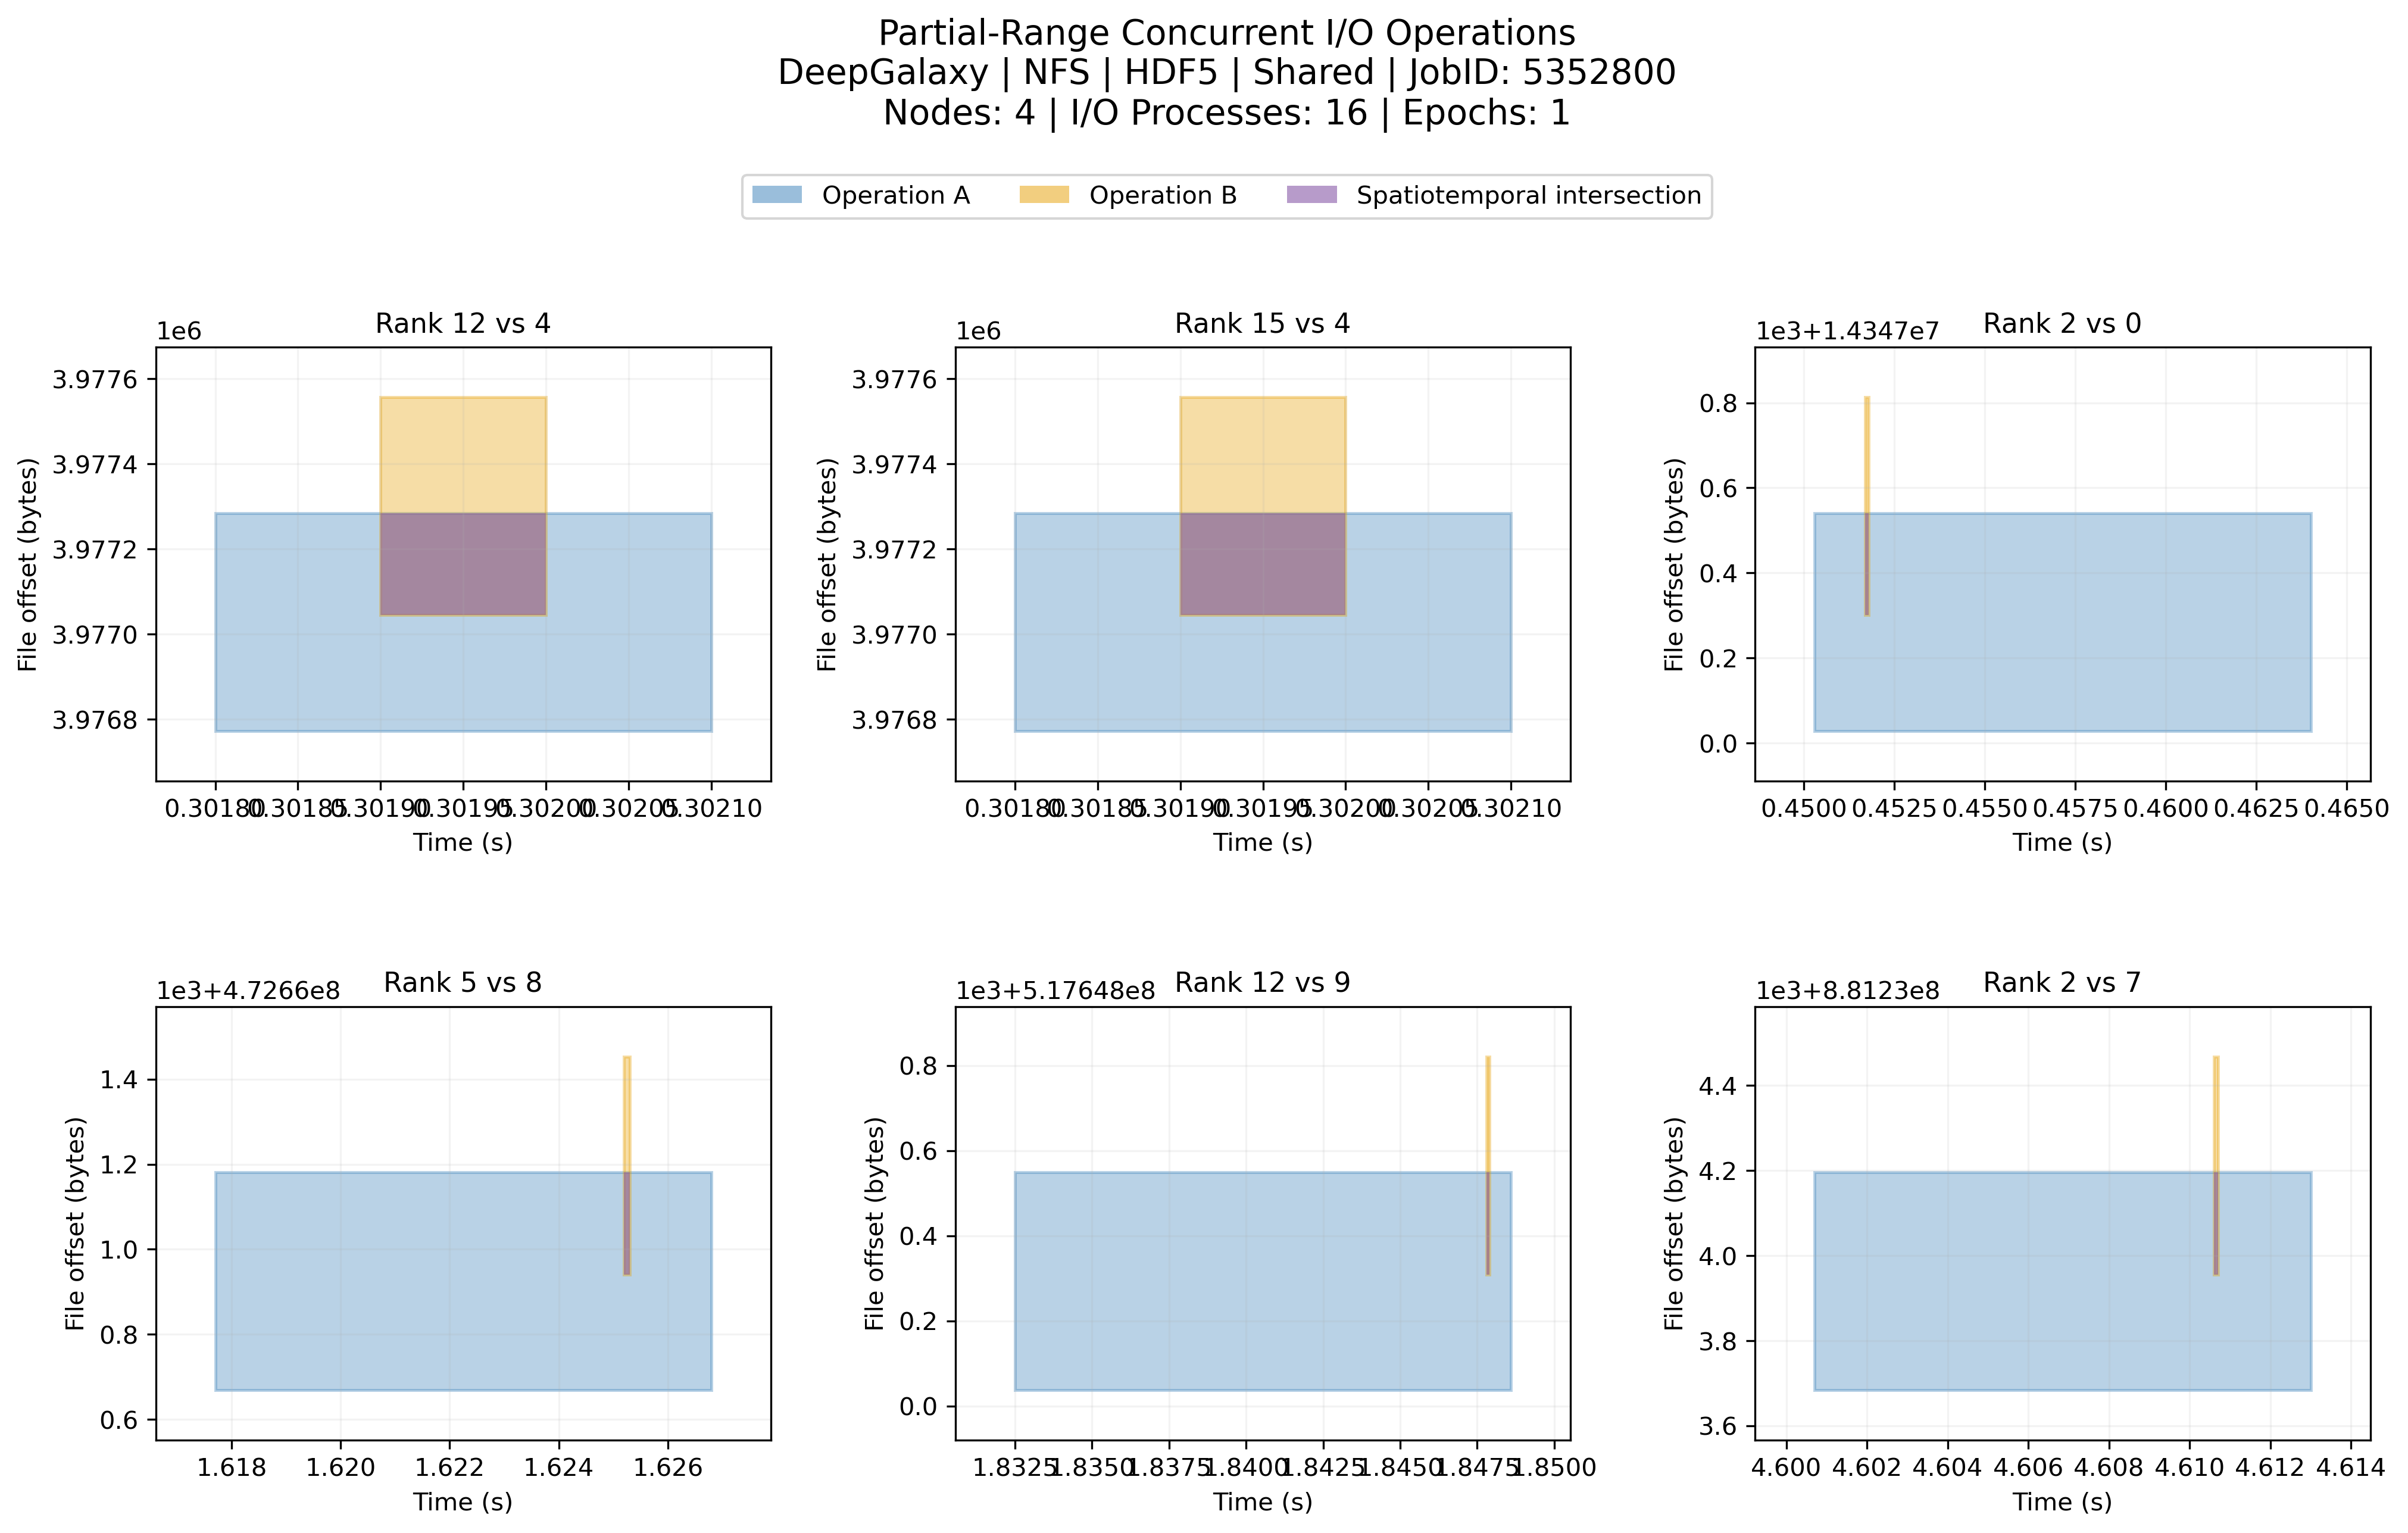

15_shared_resource_concurrent_io


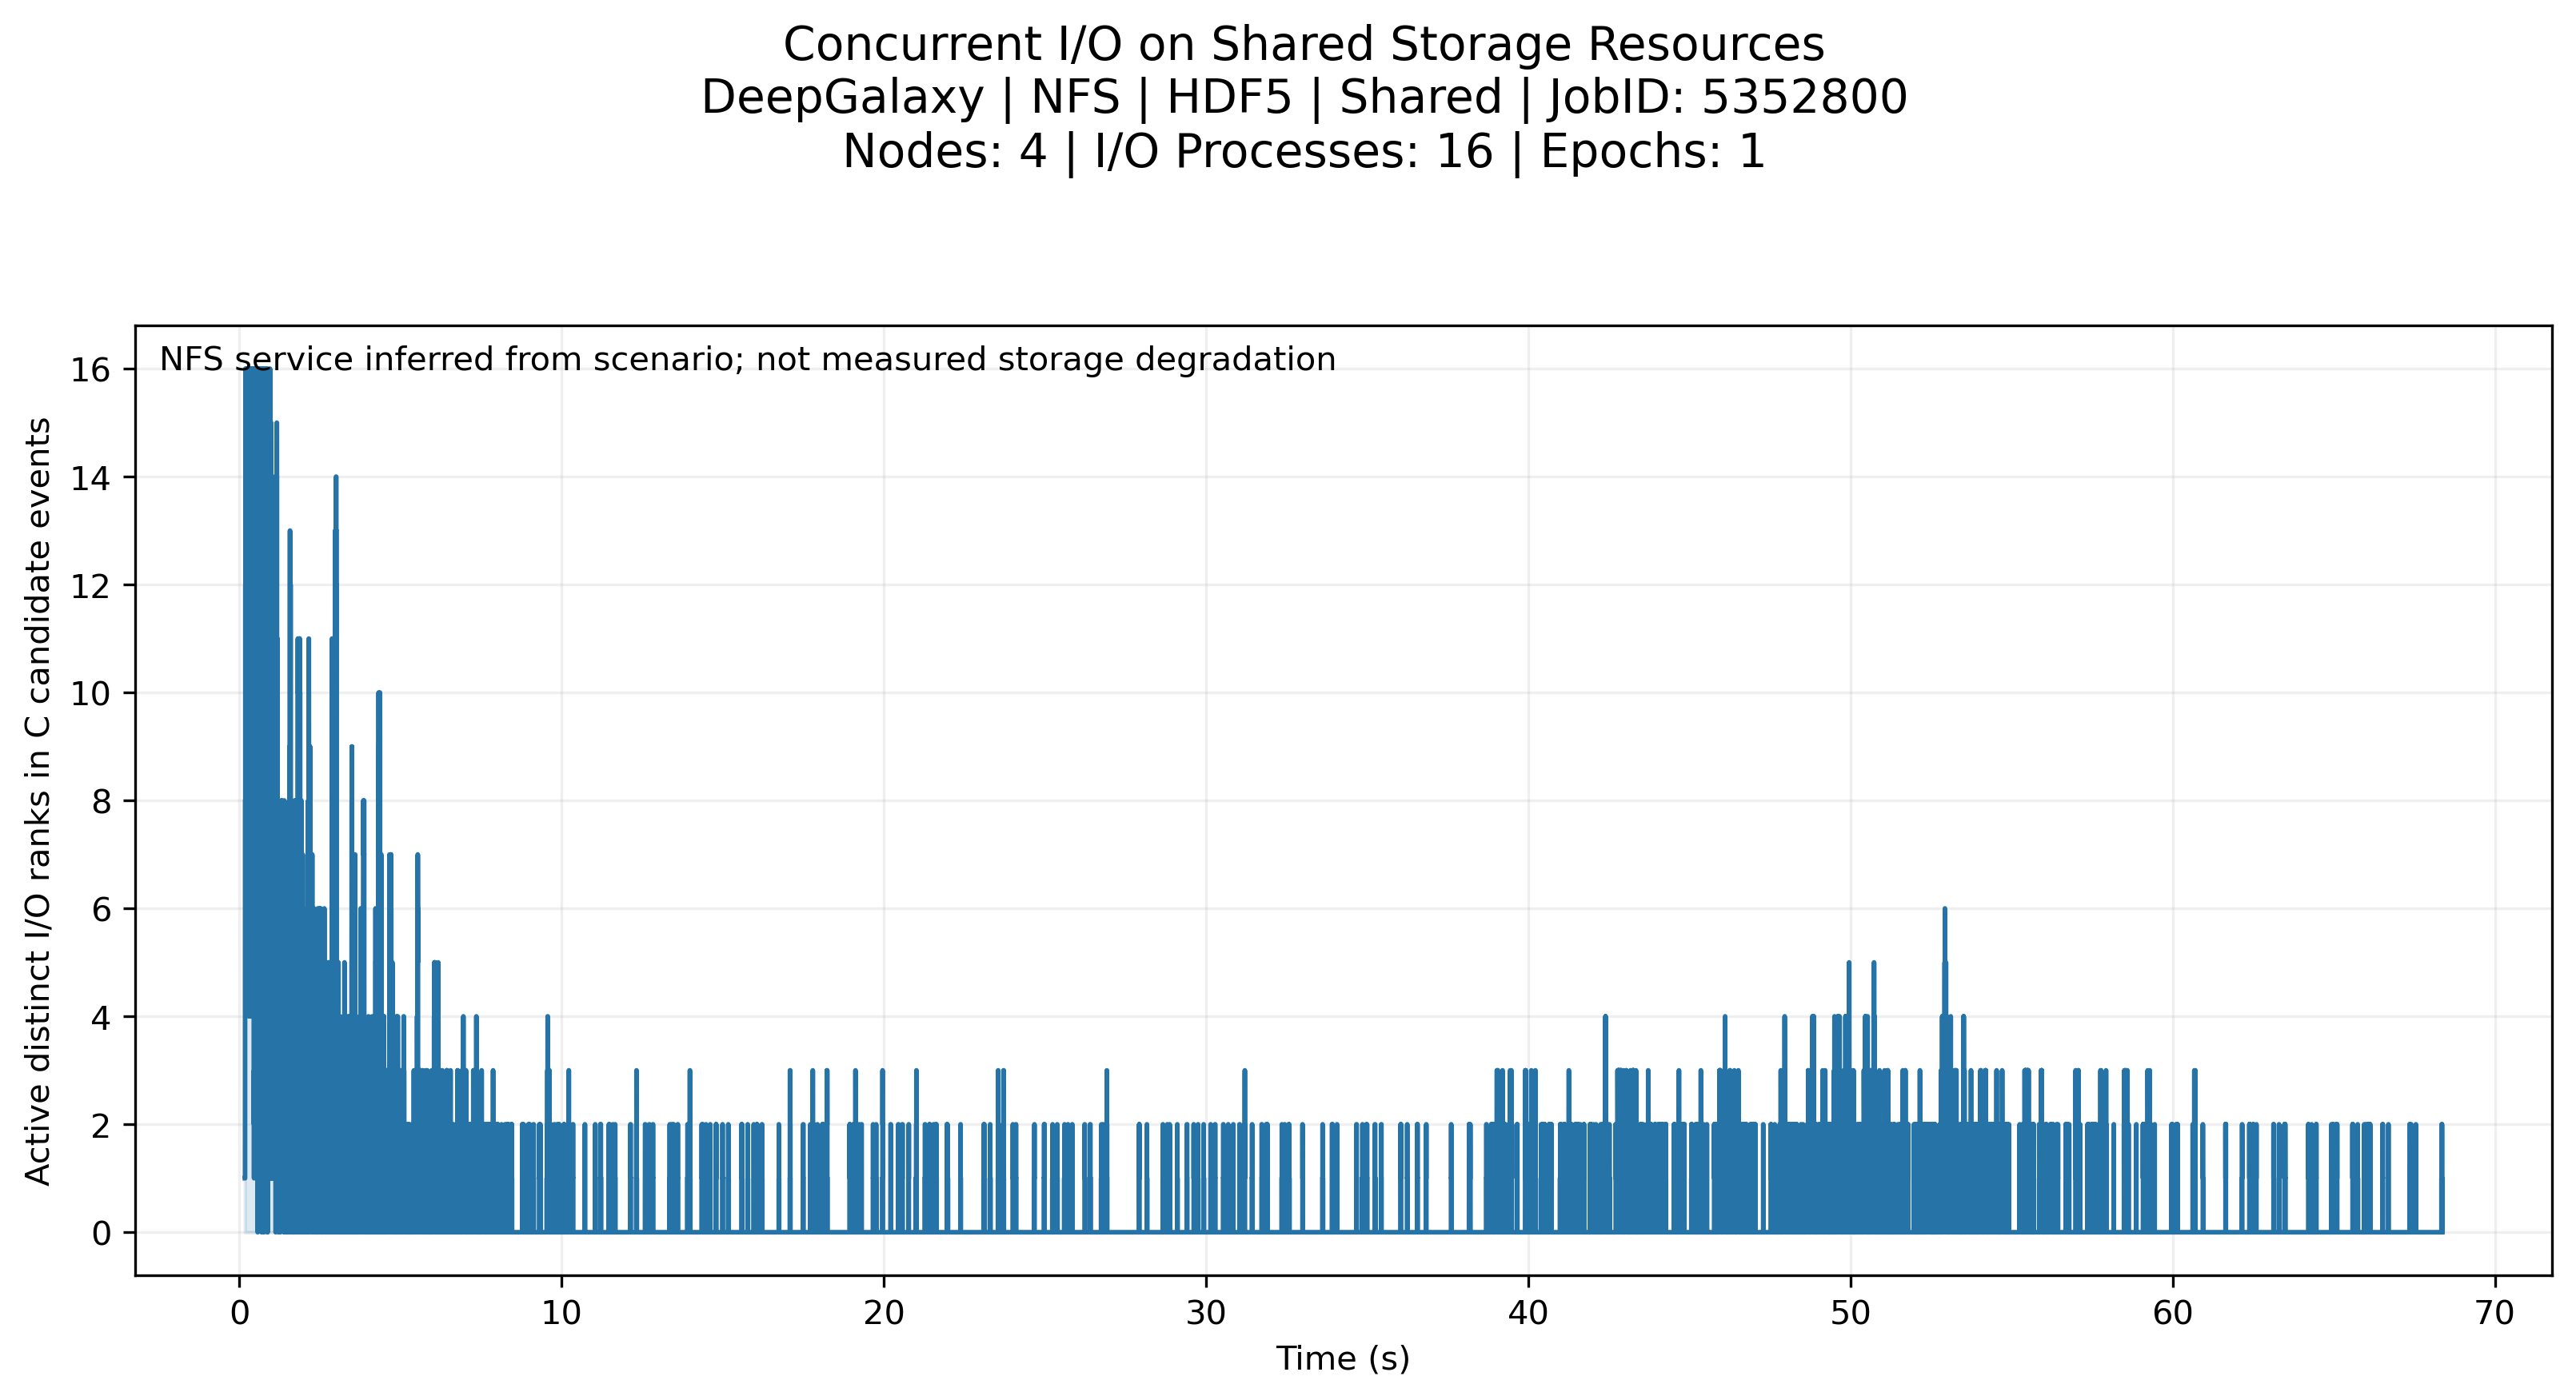

In [56]:
from IPython.display import display, Image
for stem in ("13_exact_range_concurrent_io", "14_partial_range_concurrent_io", "15_shared_resource_concurrent_io"):
    image_path = OUTPUT_ROOT / (stem + ".png")
    if image_path.exists():
        print(stem)
        display(Image(filename=str(image_path), width=950))
    else:
        print("No generado:", image_path)
